# Inclui+ Vision: treinamento e avaliação

Passos 3 e 4 do projeto, para rodar no **Google Colab**.

Antes de começar, ative a GPU: **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4**.

O notebook só orquestra. A lógica fica nos scripts de `src/`, que também rodam no computador:

| Etapa | O que acontece | Script |
|---|---|---|
| 1 a 3 | Ambiente, código e imagens | |
| 4 | Une as fontes, unifica as classes e divide em 70/20/10 | `src/preparar_dataset.py` |
| 5 | Mostra imagens com as anotações, para conferir o mapa de classes | `src/ver_amostras.py` |
| 6 | Fine-tuning do YOLO11 a partir dos pesos do COCO | (aqui) |
| 7 | Métricas no conjunto de teste, matriz de confusão e exemplos | `src/avaliar.py` |
| 8 | Experimentos do relatório: `yolo11n` × `yolo11s` e com × sem fotos próprias | |
| 9 | Guarda os pesos e os resultados no Drive | |

## 1. Configuração e ambiente

In [4]:
# Ajuste estes valores e rode as células na ordem.
REPO_URL = "https://github.com/Luzquinhas/inclui-vision.git"
PASTA_DRIVE = "/content/drive/MyDrive/inclui-vision"   # .zip dos datasets e treinos salvos
MODELO_BASE = "yolo11n.pt"   # "n" = nano (mais rápido); "s" = small (mais preciso)
EPOCAS = 100
IMGSZ = 640
BATCH = 16

In [2]:
%pip install -q "ultralytics>=8.3.0" albumentations

import os, shutil, subprocess, zipfile
from pathlib import Path

import torch
import ultralytics
from IPython.display import Image, display

ultralytics.checks()
#assert torch.cuda.is_available(), (
#    "Sem GPU. Ative em Ambiente de execução > Alterar o tipo de ambiente de execução > GPU T4."
#)

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/107.7 GB disk)


In [5]:
# O Drive guarda os .zip dos datasets e os treinos, para nada se perder se o Colab desconectar.
from google.colab import drive
drive.mount("/content/drive")

Path(PASTA_DRIVE, "brutos").mkdir(parents=True, exist_ok=True)
Path(PASTA_DRIVE, "runs").mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Código do projeto

In [6]:
RAIZ = Path("/content/inclui-vision")

if not RAIZ.exists():
    if REPO_URL:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(RAIZ)], check=True)
    else:
        from google.colab import files
        enviado = files.upload()          # escolha o inclui-vision.zip
        with zipfile.ZipFile(next(iter(enviado))) as z:
            z.extractall("/content")

assert (RAIZ / "src" / "preparar_dataset.py").exists(), "Não achei o repositório em /content/inclui-vision."
os.chdir(RAIZ)
for pasta in ("results", "weights"):
    Path(pasta).mkdir(exist_ok=True)
print("Pasta de trabalho:", Path.cwd())

Pasta de trabalho: /content/inclui-vision


## 3. Imagens

Coloque em `MyDrive/inclui-vision/brutos/` um `.zip` por fonte, exportado no formato **YOLOv11** (ou YOLOv8, que é igual em disco):

- datasets públicos do Roboflow Universe (botão *Download Dataset*);
- as fotos do grupo, anotadas no Roboflow ou no CVAT;
- opcionalmente, um `.zip` só com fotos sem nenhum recurso de acessibilidade (`negativas.zip`).

O nome de cada `.zip` deve ser o da `pasta` correspondente em `dataset/fontes.yaml` (por exemplo, `stairs-handrail.zip`). Deixe em `fontes.yaml` só as fontes que você realmente baixou.

Se a versão do Roboflow já tiver *augmentation*, gere uma versão sem: o treino abaixo já aplica augmentation, e só no conjunto de treino.

In [7]:
BRUTOS = RAIZ / "dataset" / "brutos"
BRUTOS.mkdir(parents=True, exist_ok=True)

zips = sorted(Path(PASTA_DRIVE, "brutos").glob("*.zip"))
assert zips, f"Nenhum .zip em {PASTA_DRIVE}/brutos."

for arquivo in zips:
    destino = BRUTOS / arquivo.stem
    if not destino.exists():
        with zipfile.ZipFile(arquivo) as z:
            z.extractall(destino)
    n = sum(1 for p in destino.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    print(f"{arquivo.stem}: {n} imagens")

braille-block: 787 imagens
detector-rampas: 2230 imagens
stairs-barrierfree: 150 imagens
stairs-handrail: 451 imagens


## 4. Preparar o dataset

Lê `dataset/fontes.yaml`, traduz as classes de cada fonte para as do projeto, divide em **70% treino, 20% validação e 10% teste** e grava `dataset/data.yaml`.

Leia os avisos no fim da saída: eles dizem quais classes estão com poucas imagens. A tabela também fica em `dataset/resumo.md`, pronta para o relatório.

In [8]:
import subprocess, sys

r = subprocess.run(
    [sys.executable, "src/preparar_dataset.py", "--config", "dataset/fontes.yaml", "--saida", "dataset", "--limpar"],
    capture_output=True, text=True,
)
print(r.stdout, r.stderr)
assert r.returncode == 0, "A preparação falhou. Leia a linha ERRO acima e corrija antes de treinar."

Fontes lidas:
  stairs-handrail: 451 imagens
  stairs-barrierfree: 150 imagens
  detector-rampas: 2230 imagens
    classes sem destino (caixas descartadas): ------------------------------
    caixas descartadas por classe de origem: ------------------------------: 156
  braille-block: 787 imagens
    classes sem destino (caixas descartadas): no_braille_block
    caixas descartadas por classe de origem: no_braille_block: 260
    231 imagens ficaram sem nenhuma caixa e foram deixadas de fora
Cópias aumentadas removidas da validação e do teste: 505

| Classe | Imagens no treino | Imagens na validação | Imagens no teste | Caixas (total) |
| --- | ---: | ---: | ---: | ---: |
| `rampa` | 1568 | 108 | 54 | 1777 |
| `escada` | 416 | 109 | 54 | 721 |
| `corrimao` | 231 | 65 | 32 | 531 |
| `piso_tatil` | 389 | 111 | 56 | 592 |
| Sem nenhum recurso (negativas) | 12 | 3 | 2 | 0 |
| **Total de imagens** | **2385** | **331** | **166** | **3621** |

AVISO: Abaixo da meta de 300 a 800 imagens no trein

## 5. Conferir as anotações

Olhe a grade antes de treinar. Se uma rampa aparecer marcada como escada, o mapa de classes em `fontes.yaml` está errado, e é melhor descobrir agora.

Grade com 12 imagens salva em results/amostras_treino.jpg


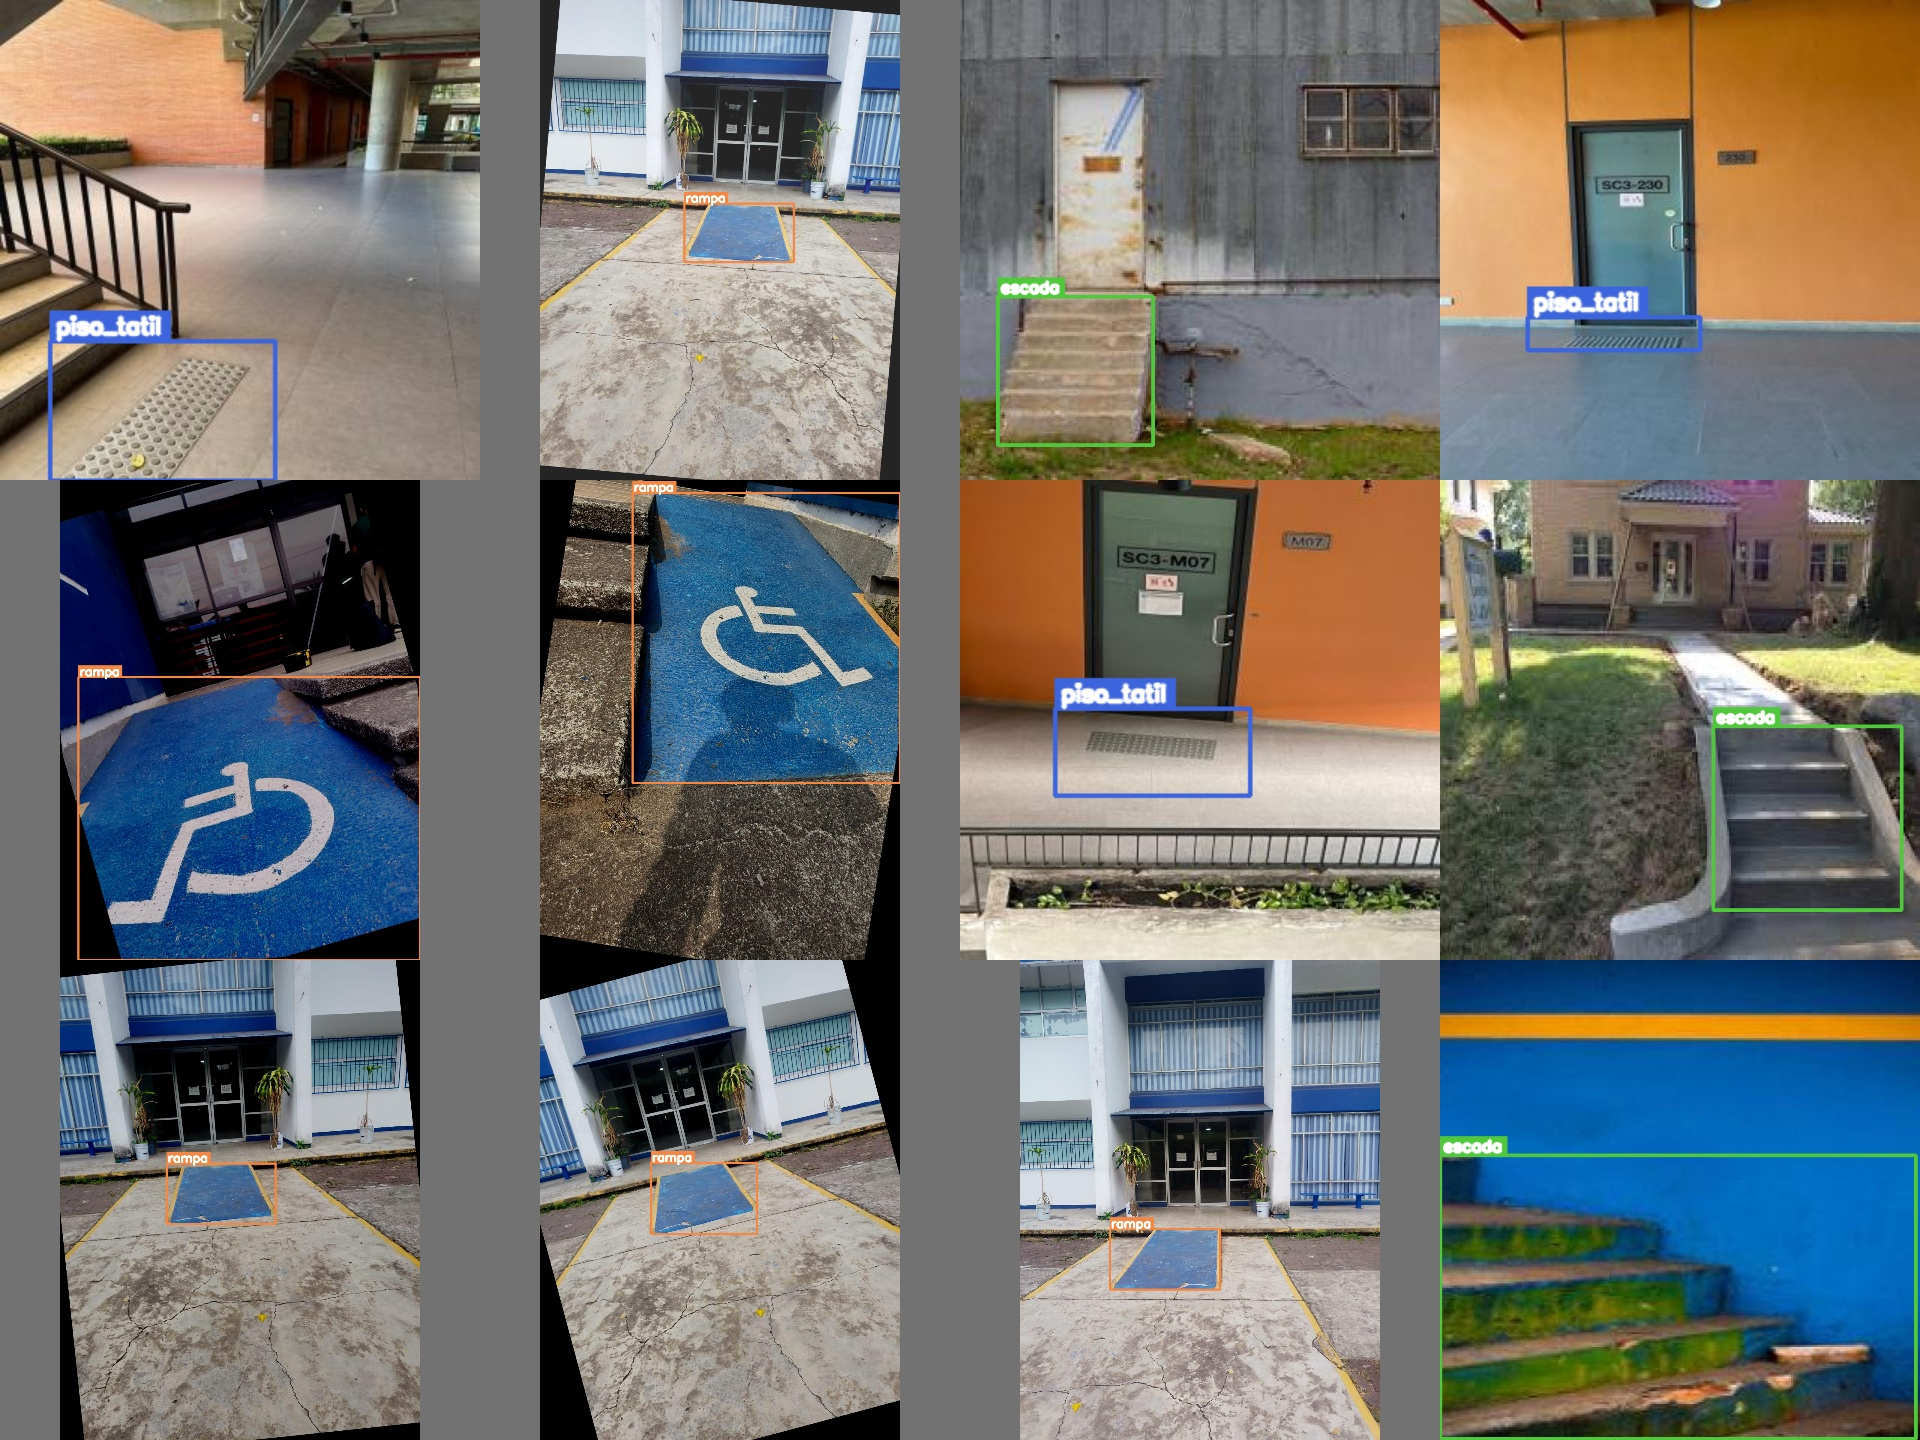

In [16]:
!python src/ver_amostras.py --n 12 --saida results/amostras_treino.jpg
display(Image("results/amostras_treino.jpg", width=1100))

## 6. Treinamento

*Fine-tuning*: o modelo parte dos pesos pré-treinados no COCO e aprende as classes novas.

A *augmentation* é aplicada pelo Ultralytics durante o treino, e só nele: flip horizontal, variação de brilho e rotação de até ±15°, além das transformações padrão da biblioteca (mosaic, escala, translação, matiz e saturação). Com o pacote `albumentations` instalado, entram também, com baixa probabilidade, blur leve e ajuste de contraste.

Os treinos são salvos em `MyDrive/inclui-vision/runs/`.

In [ ]:
from ultralytics import YOLO

def treinar(nome, base=MODELO_BASE, data="dataset/data.yaml"):
    """Treina e devolve o caminho do best.pt."""
    modelo = YOLO(base)                 # pesos pré-treinados no COCO (transfer learning)
    modelo.train(
        data=str(RAIZ / data),
        epochs=EPOCAS,
        imgsz=IMGSZ,
        batch=BATCH,
        patience=20,                    # early stopping se não melhorar
        project=f"{PASTA_DRIVE}/runs",
        name=nome,
        exist_ok=True,
        seed=0,
        fliplr=0.5,                     # flip horizontal
        hsv_v=0.4,                      # brilho
        degrees=15,                     # rotação de até ±15°
    )
    return Path(modelo.trainer.best)

melhor = treinar("inclui_vision")
print("Melhores pesos:", melhor)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/inclui-vision/dataset/data.yaml, degrees=15, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=inclui_vision, nbs=64, nms=None, opset=None, opti

In [19]:
from pathlib import Path
pesos = Path(PASTA_DRIVE, "runs", "inclui_vision", "weights")
print("best.pt:", (pesos / "best.pt").exists(), "| last.pt:", (pesos / "last.pt").exists())
melhor = pesos / "best.pt"

best.pt: True | last.pt: True


In [18]:
# Se o Colab desconectar no meio do treino, monte o Drive de novo, rode as células 1 e 2
# e descomente as linhas abaixo para continuar de onde parou.
#
from ultralytics import YOLO
modelo = YOLO(f"{PASTA_DRIVE}/runs/inclui_vision/weights/last.pt")
modelo.train(resume=True)
melhor = Path(modelo.trainer.best)

WARNING ⚠️ model '/content/drive/MyDrive/inclui-vision/runs/inclui_vision/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=Non

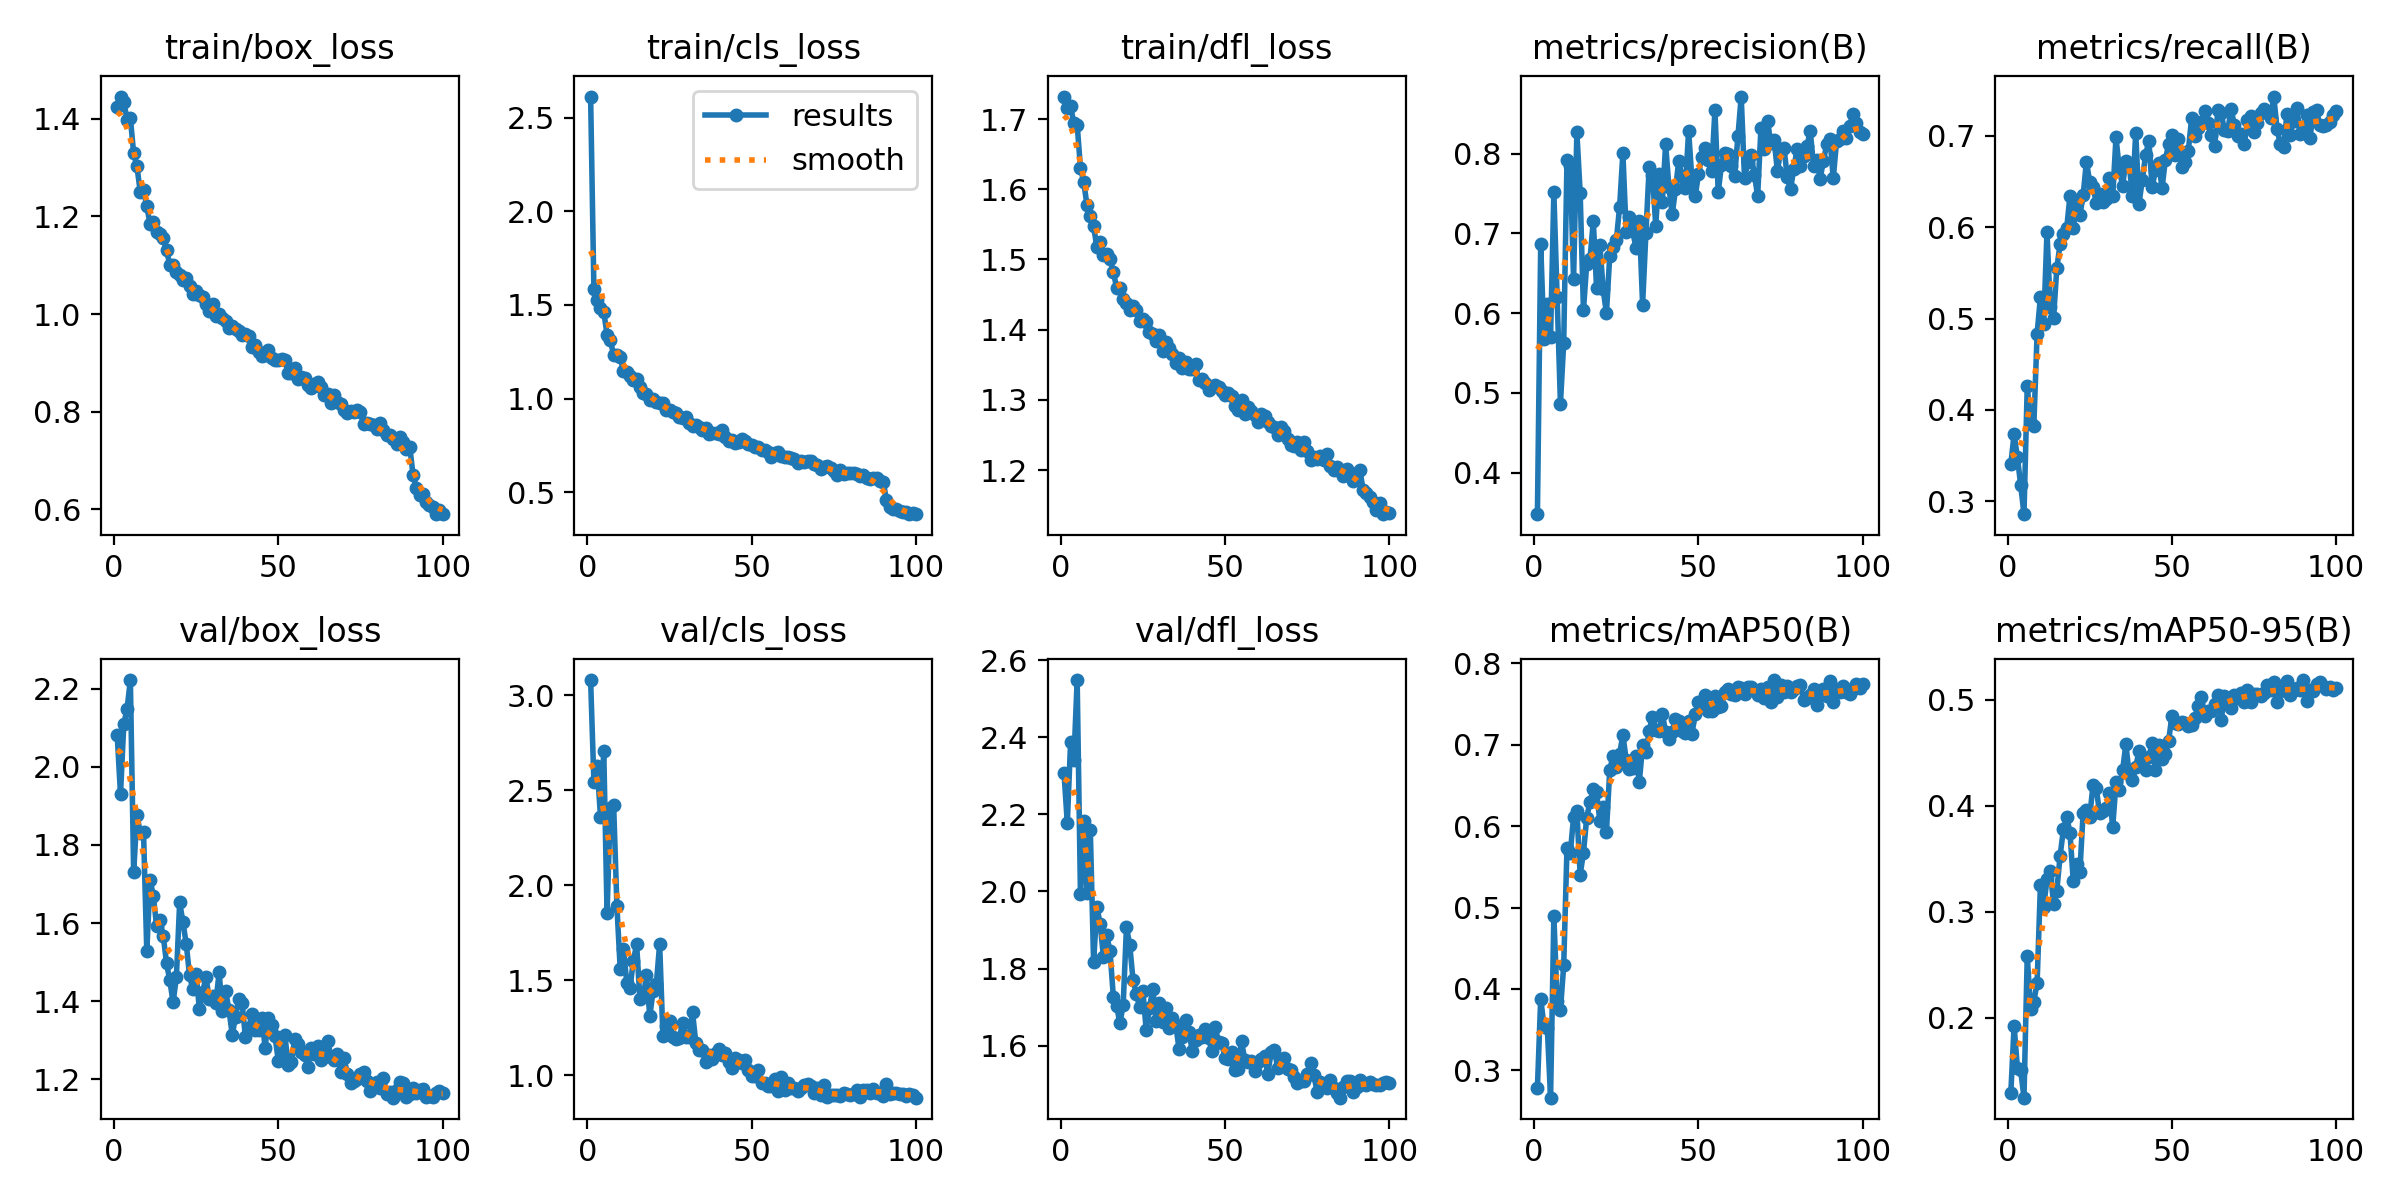

In [20]:
# Curvas de loss e de mAP por época, e os pesos finais no lugar que os scripts esperam.
pasta_treino = melhor.parents[1]
shutil.copy2(pasta_treino / "results.png", "results/results.png")
shutil.copy2(pasta_treino / "results.csv", "results/results.csv")
shutil.copy2(melhor, "weights/best.pt")
display(Image("results/results.png", width=1100))

## 7. Avaliação no conjunto de teste

O conjunto de teste não foi usado no treino nem na escolha do melhor modelo. As tabelas saem em `results/metricas.md`, prontas para o relatório.

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1615.9±1121.0 MB/s, size: 151.4 KB)
val: Scanning /content/inclui-vision/dataset/test/labels... 166 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 166/166 1.7Kit/s 0.1s
val: New cache created: /content/inclui-vision/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.6it/s 4.3s
                   all        166        229      0.814      0.745      0.797      0.561
Speed: 2.1ms preprocess, 6.5ms inference, 0.0ms loss, 3.9ms postprocess per image
Results saved to /content/inclui-vision/results/validacao/yolo11n
### Métricas gerais (yolo11n, conjunto de teste)

| mAP@50 | mAP@50-95 | Precisão | Recall | Tempo por imagem | FPS |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 0.797 | 

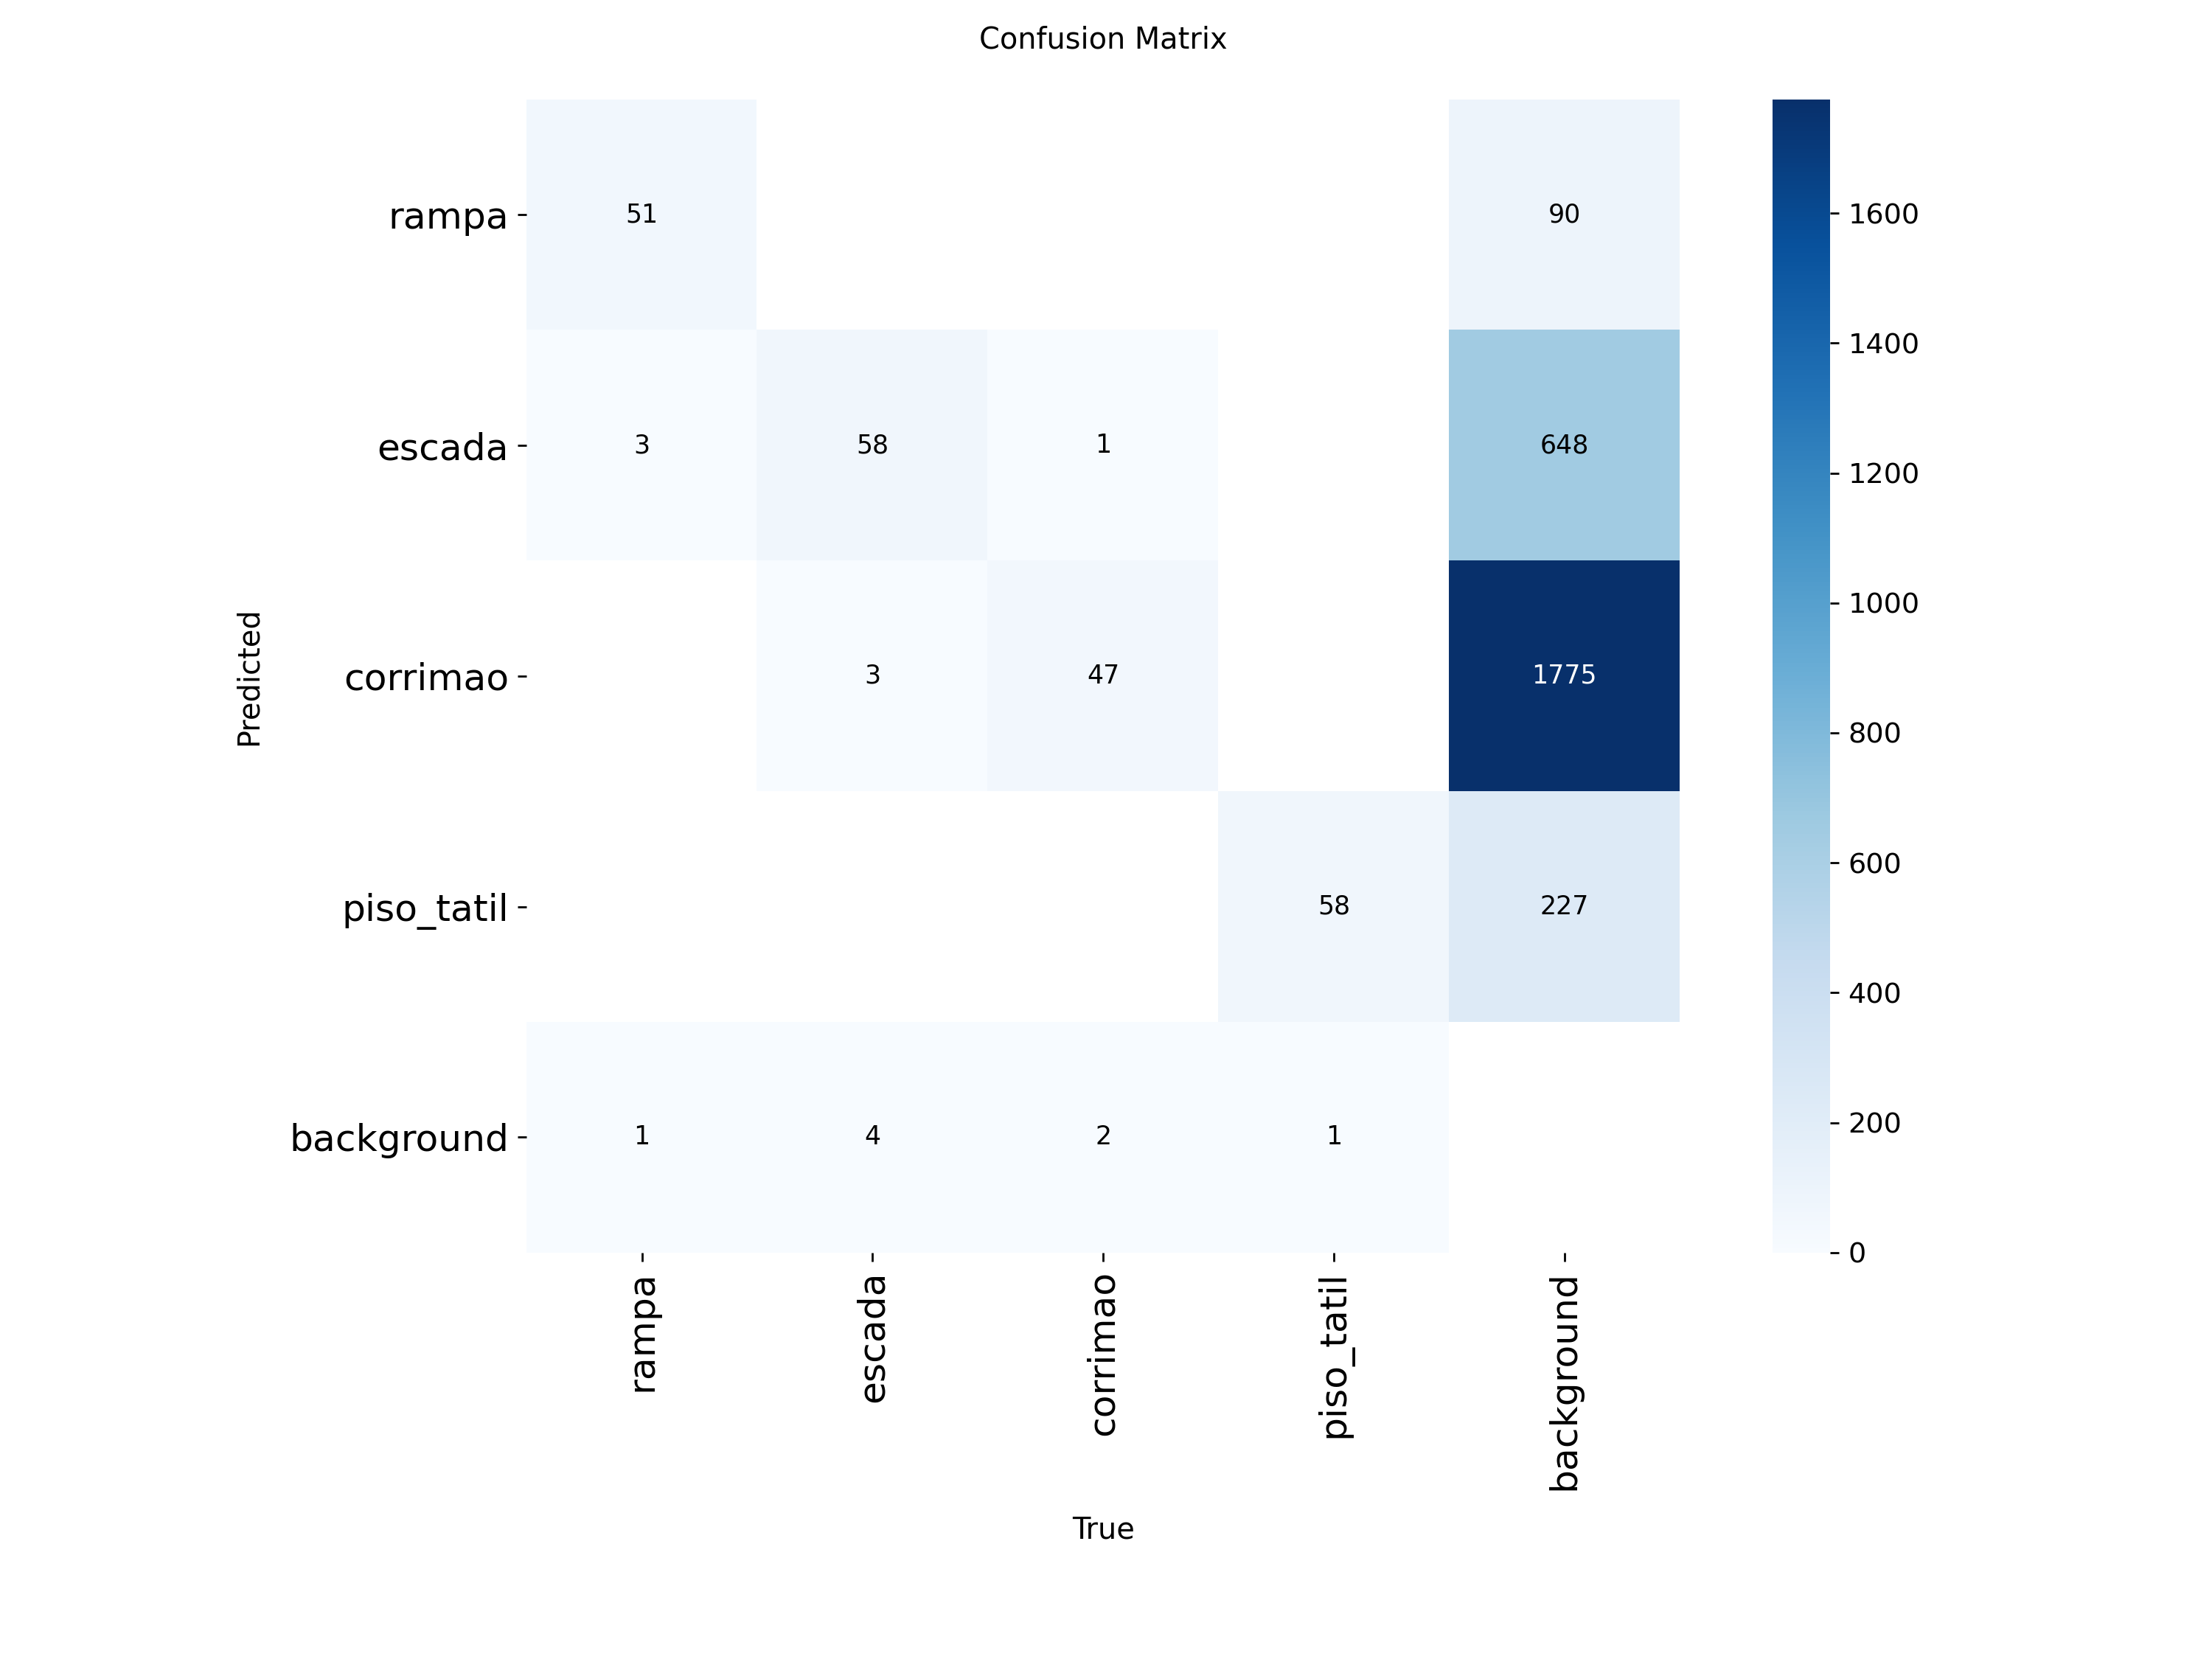

In [21]:
ROTULO = Path(MODELO_BASE).stem      # yolo11n
!python src/avaliar.py --pesos weights/best.pt --data dataset/data.yaml --split test --rotulo {ROTULO} --saida results
display(Image("results/confusion_matrix.png", width=750))

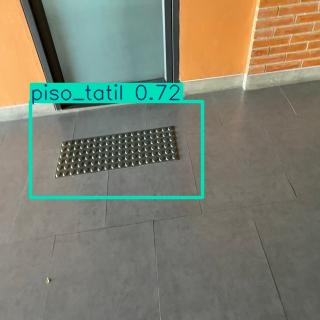

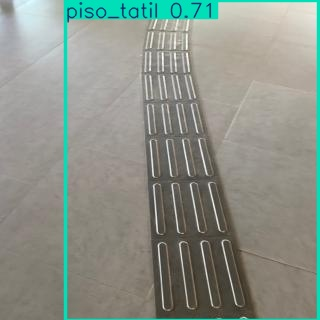

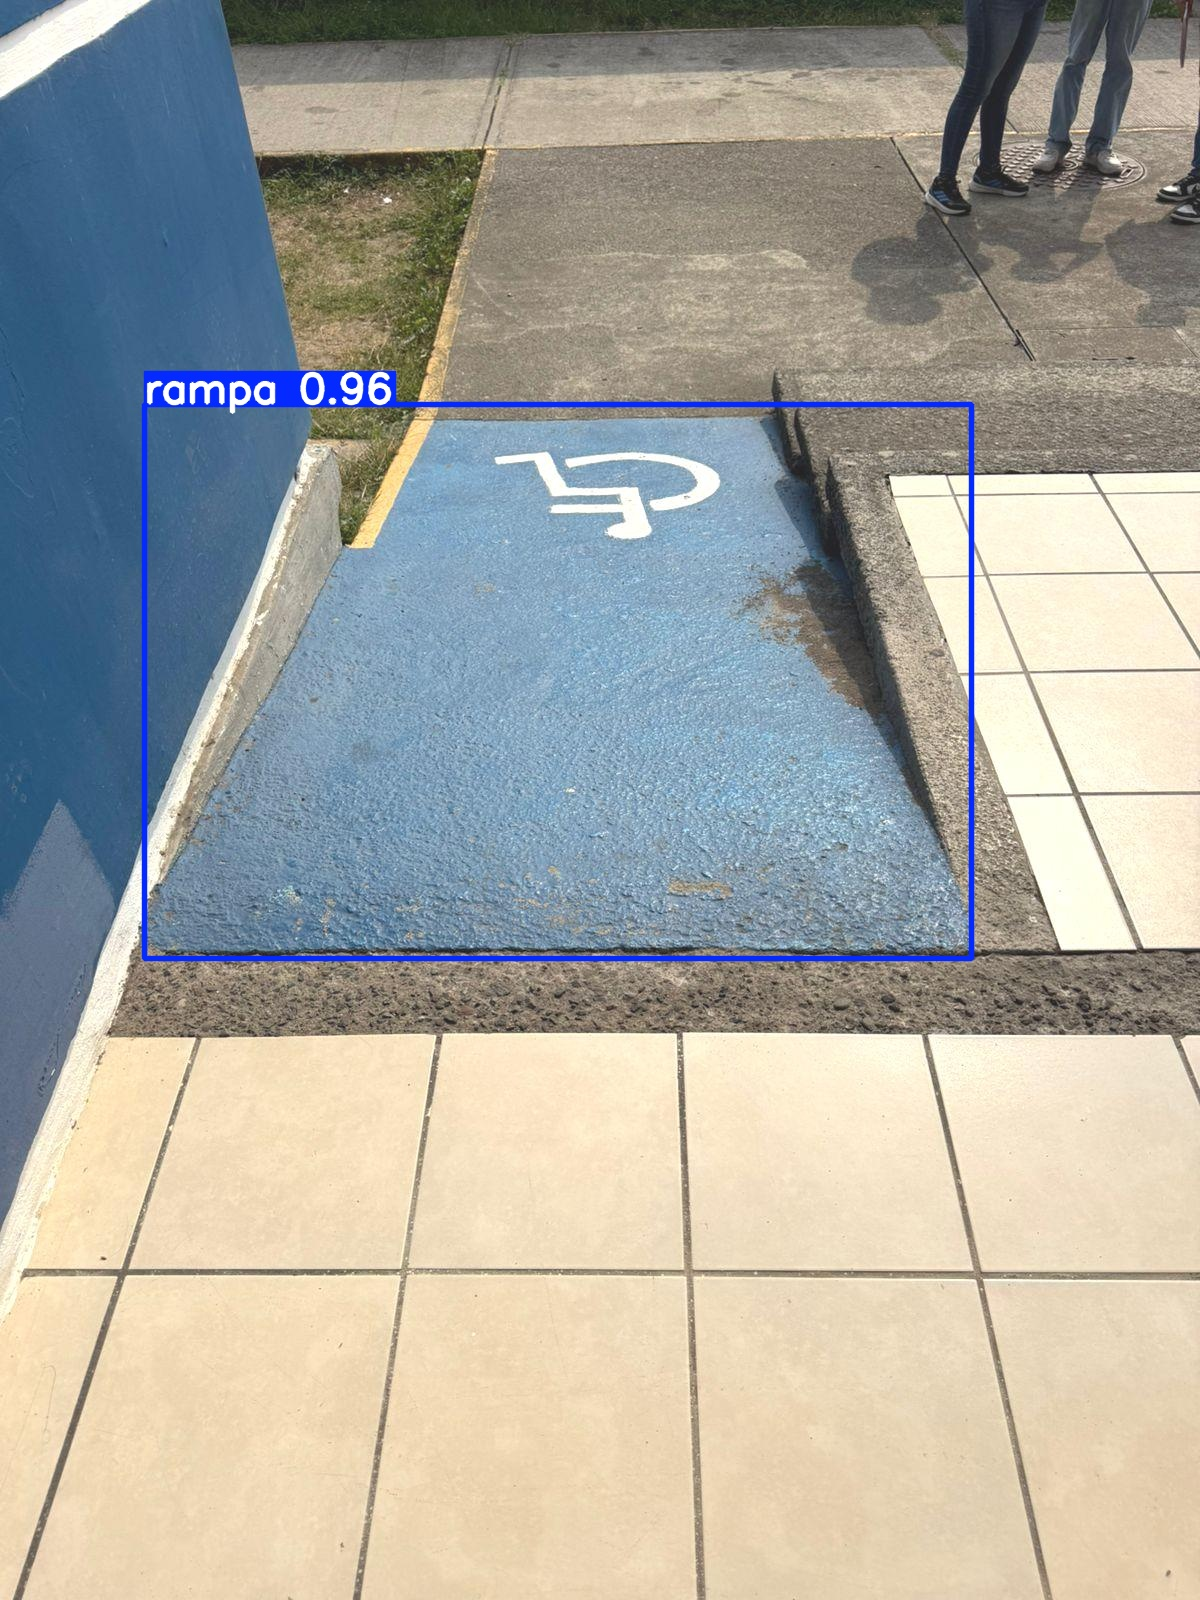

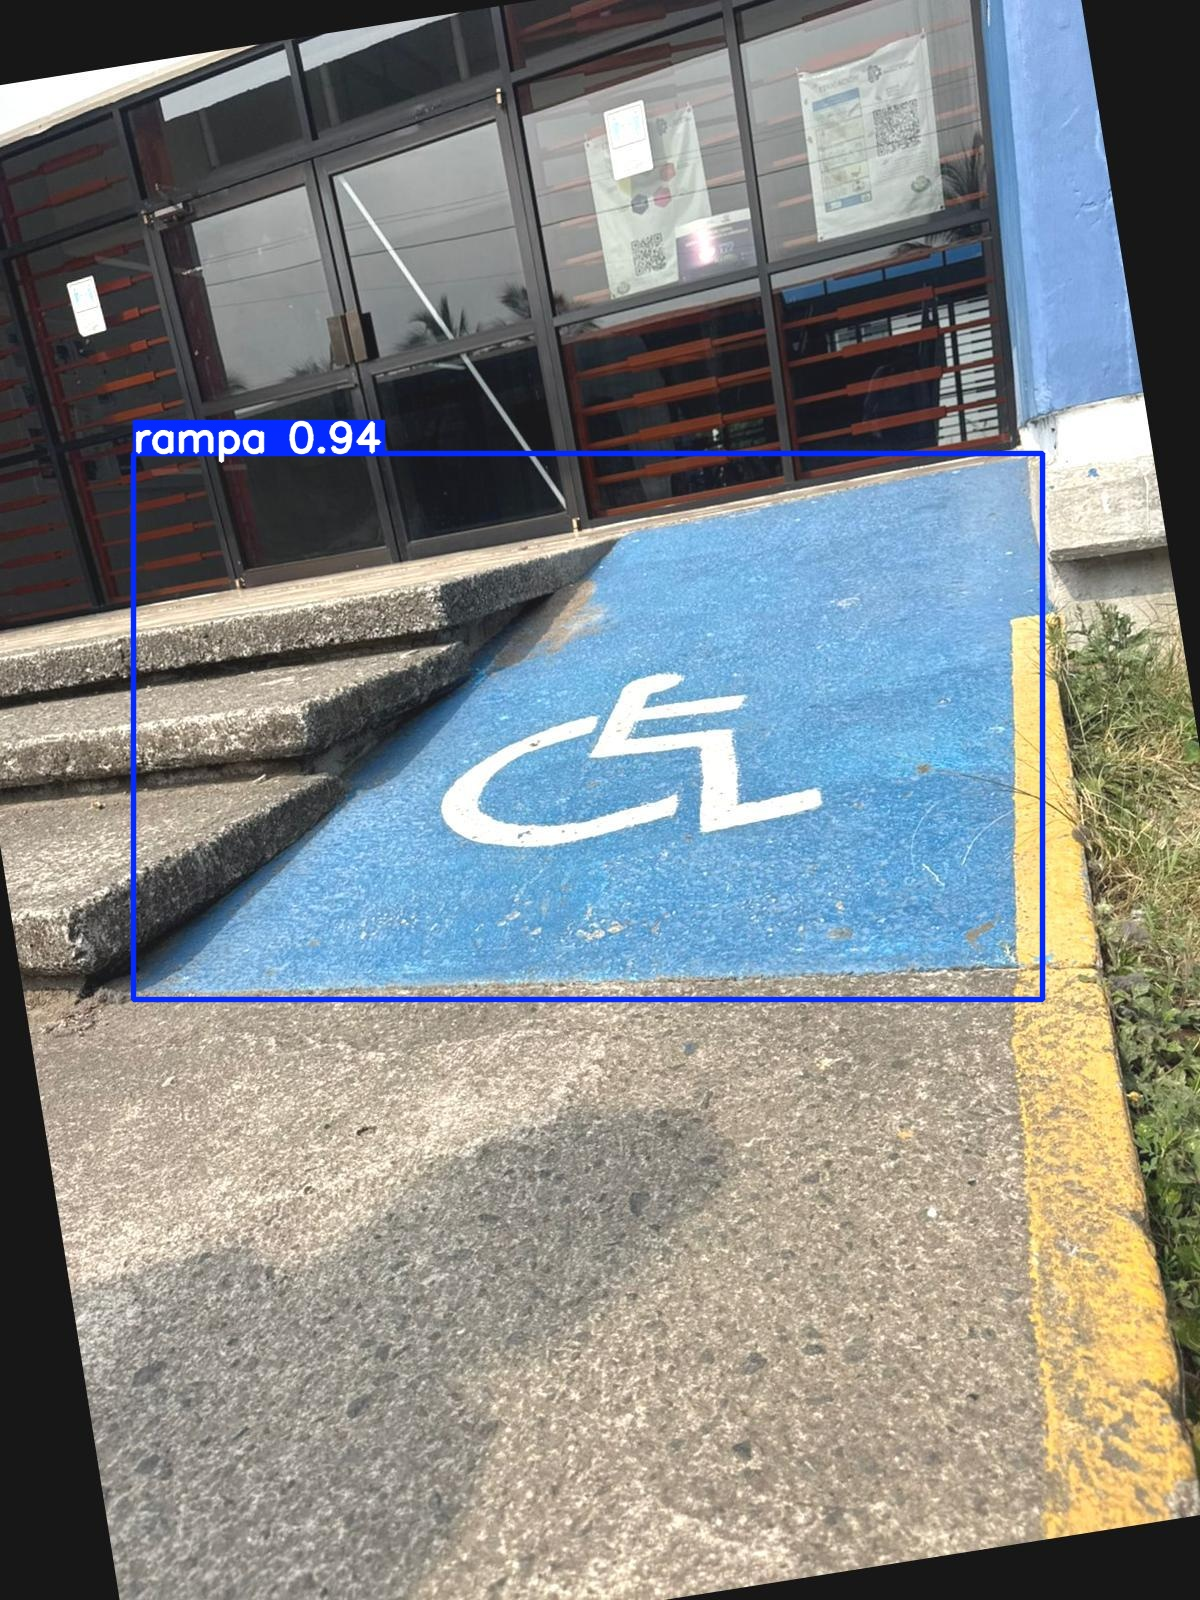

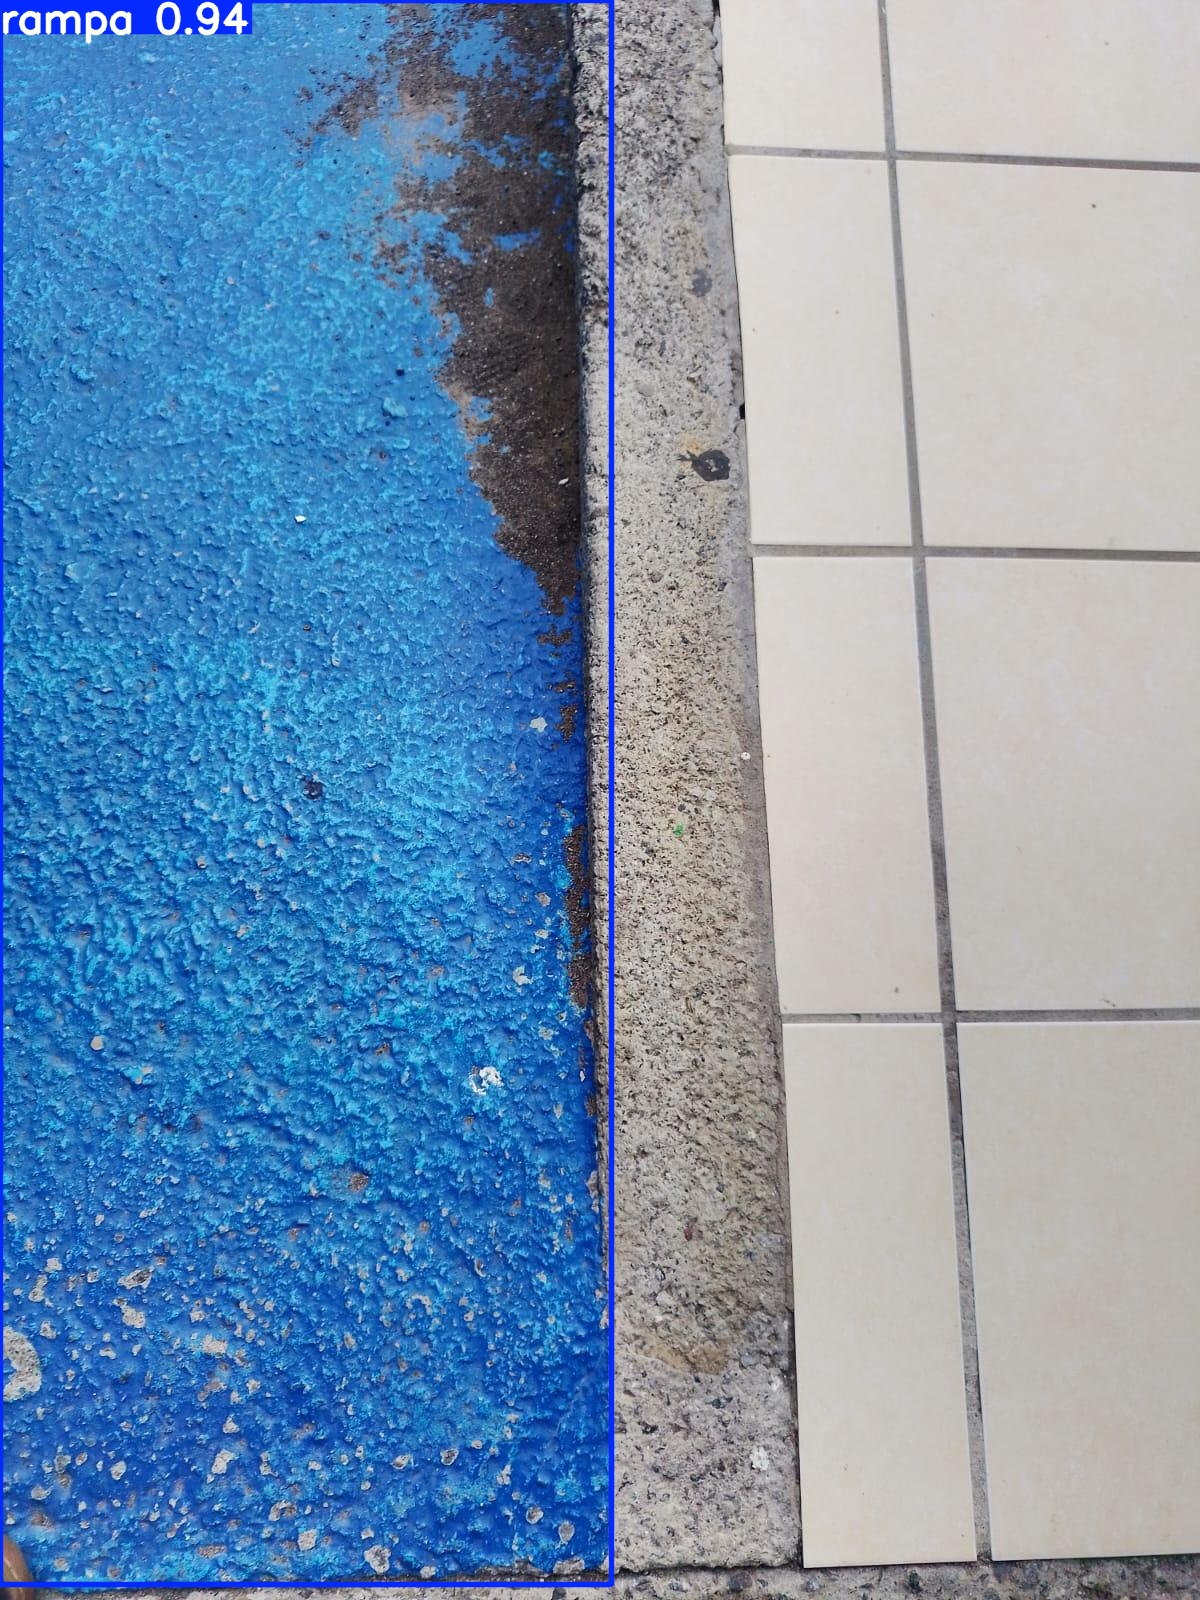

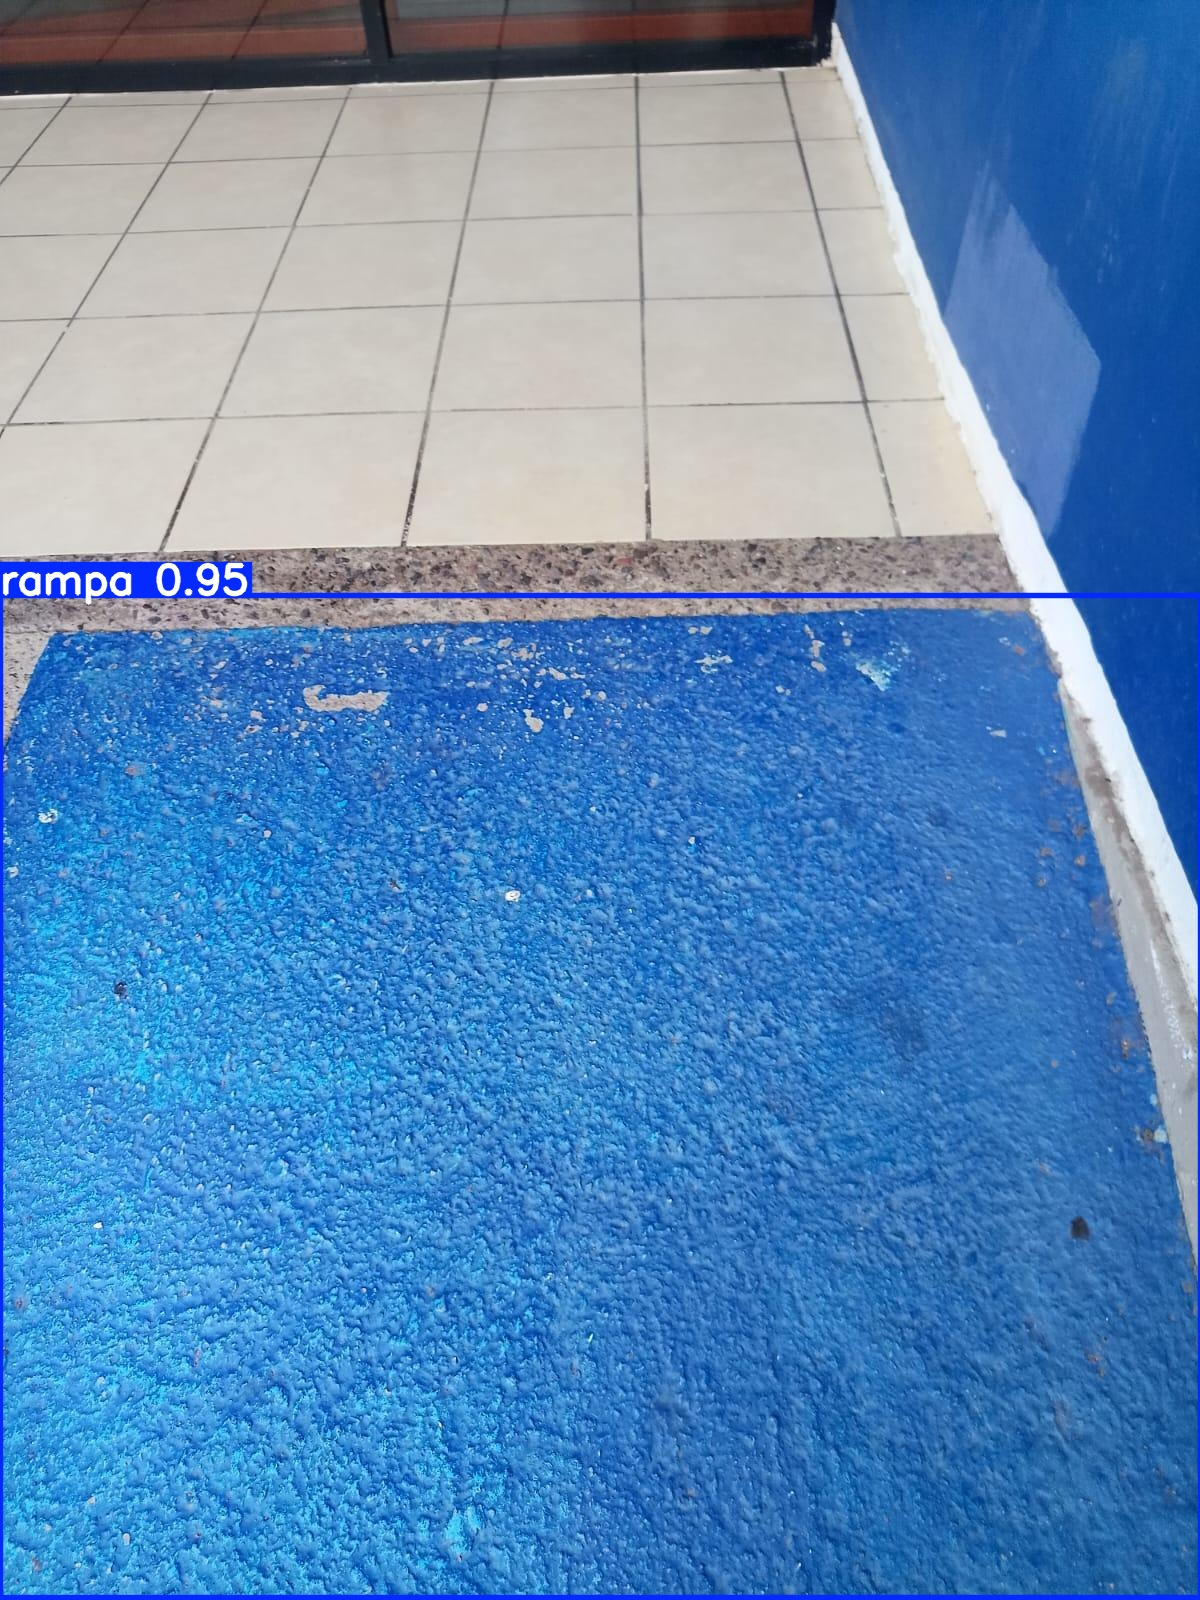

In [24]:
# Prints de inferência: imagens de teste com as bounding boxes previstas.
for exemplo in sorted(Path("results/exemplos").glob("*.jpg"))[:6]:
    display(Image(str(exemplo), width=520))

## 8. Guardar os resultados

Copia tudo para `MyDrive/inclui-vision/entrega/` e baixa um `.zip`. Depois, no computador, ponha o `best.pt` em `weights/` e os arquivos de `results/` no repositório.

In [12]:
melhor = Path(PASTA_DRIVE, "runs", "inclui_vision", "weights", "best.pt")
shutil.copy2(melhor.parents[1] / "results.png", "results/results.png")
shutil.copy2(melhor.parents[1] / "results.csv", "results/results.csv")
shutil.copy2(melhor, "weights/best.pt")
print("ok:", melhor.exists())

ok: True
